# Day 95 — What is Deep Learning? Deep Learning vs Machine Learning

Hands-on comparison on the **handwritten digits** dataset (8x8 images):

1. **Machine Learning way:** manually engineered features + Random Forest
2. **Deep Learning way:** raw pixels + neural network (features learned automatically)
3. Effect of **training data size**
4. **Training time** comparison
5. **Visualizing features** learned by the network's first layer

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

np.random.seed(42)

## 1. Load and look at the data

Data shape: (1797, 64) (1797 images, 64 pixels each)


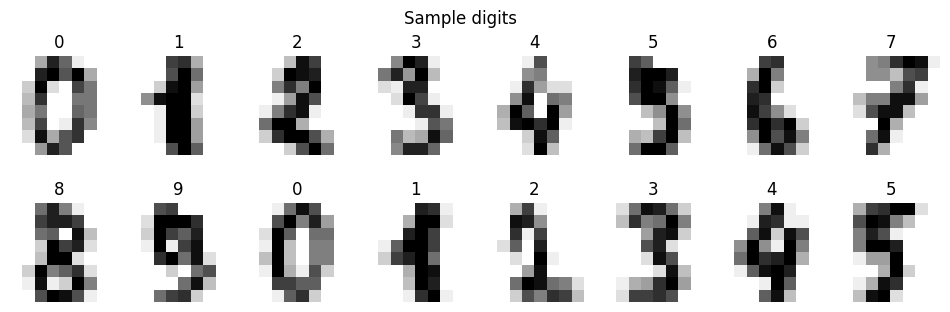

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print("Data shape:", X.shape, "(1797 images, 64 pixels each)")

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(label); ax.axis("off")
plt.suptitle("Sample digits"); plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

## 2. Machine Learning way: manual feature engineering

A human decides which features matter. Here we design 21 features per image:
total ink (1), ink per row (8), ink per column (8), plus top, bottom, left and right half ink (4).

In [3]:
def handcrafted_features(X_flat):
    imgs = X_flat.reshape(-1, 8, 8)
    total   = imgs.sum(axis=(1, 2))
    rows    = imgs.sum(axis=2)            # 8 features
    cols    = imgs.sum(axis=1)            # 8 features
    top     = imgs[:, :4, :].sum(axis=(1, 2))
    bottom  = imgs[:, 4:, :].sum(axis=(1, 2))
    left    = imgs[:, :, :4].sum(axis=(1, 2))
    right   = imgs[:, :, 4:].sum(axis=(1, 2))
    return np.column_stack([total, rows, cols, top, bottom, left, right])

F_train, F_test = handcrafted_features(X_train), handcrafted_features(X_test)
print("Hand-crafted feature shape:", F_train.shape)

t0 = time.time()
ml_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(F_train, y_train)
ml_time = time.time() - t0
ml_acc = ml_model.score(F_test, y_test)
print(f"ML (Random Forest + manual features): accuracy = {ml_acc:.3f}, train time = {ml_time:.2f}s")

Hand-crafted feature shape: (1257, 21)
ML (Random Forest + manual features): accuracy = 0.933, train time = 2.48s


## 3. Deep Learning way: raw pixels in, features learned automatically

No manual features. We only scale the pixels and let the network figure everything out.

In [4]:
t0 = time.time()
dl_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu",
                  max_iter=500, random_state=42)
).fit(X_train, y_train)
dl_time = time.time() - t0
dl_acc = dl_model.score(X_test, y_test)
print(f"DL (MLP on raw pixels): accuracy = {dl_acc:.3f}, train time = {dl_time:.2f}s")

DL (MLP on raw pixels): accuracy = 0.974, train time = 4.54s


In [5]:
print(f"{'Approach':35s} {'Accuracy':>9s} {'Train time':>11s}")
print(f"{'ML: manual features + RandomForest':35s} {ml_acc:9.3f} {ml_time:10.2f}s")
print(f"{'DL: raw pixels + MLP':35s} {dl_acc:9.3f} {dl_time:10.2f}s")

Approach                             Accuracy  Train time
ML: manual features + RandomForest      0.933       2.48s
DL: raw pixels + MLP                    0.974       4.54s


**Note:** results depend on the dataset and settings. Here the input is **image data**, which is where deep learning
is strong. On small **tabular** data, classical ML such as Random Forest or XGBoost is often just as good or better.

## 4. Effect of training data size

We train both approaches on growing subsets of the training data.

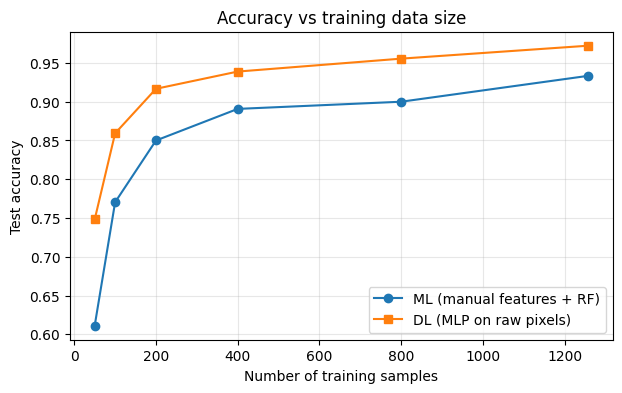

n=   50  ML=0.611  DL=0.748
n=  100  ML=0.770  DL=0.859
n=  200  ML=0.850  DL=0.917
n=  400  ML=0.891  DL=0.939
n=  800  ML=0.900  DL=0.956
n= 1257  ML=0.933  DL=0.972


In [6]:
sizes = [50, 100, 200, 400, 800, len(X_train)]
ml_scores, dl_scores = [], []

for n in sizes:
    idx = np.random.RandomState(0).permutation(len(X_train))[:n]

    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(handcrafted_features(X_train[idx]), y_train[idx])
    ml_scores.append(rf.score(F_test, y_test))

    nn = make_pipeline(StandardScaler(),
                       MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42))
    nn.fit(X_train[idx], y_train[idx])
    dl_scores.append(nn.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(sizes, ml_scores, "o-", label="ML (manual features + RF)")
plt.plot(sizes, dl_scores, "s-", label="DL (MLP on raw pixels)")
plt.xlabel("Number of training samples"); plt.ylabel("Test accuracy")
plt.title("Accuracy vs training data size"); plt.grid(alpha=0.3); plt.legend(); plt.show()

for n, a, b in zip(sizes, ml_scores, dl_scores):
    print(f"n={n:5d}  ML={a:.3f}  DL={b:.3f}")

## 5. What did the network learn? (automatic feature learning)

Each hidden neuron in the first layer has 64 weights, one per pixel. Reshaping those weights to 8x8 shows
the **pattern each neuron looks for**. Nobody told the network to look for these patterns.

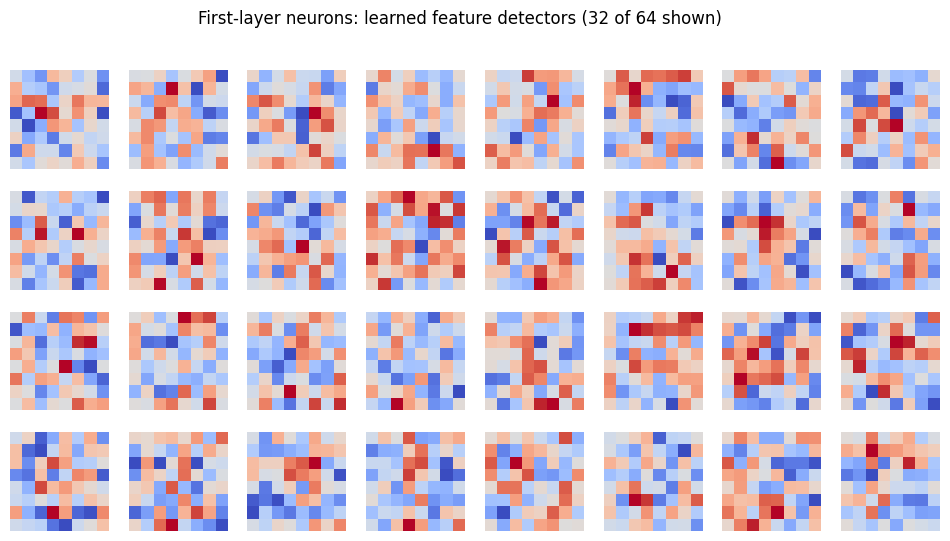

In [7]:
mlp = dl_model.named_steps["mlpclassifier"]
first_layer_weights = mlp.coefs_[0]          # shape: (64 pixels, 64 neurons)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(first_layer_weights[:, i].reshape(8, 8), cmap="coolwarm")
    ax.axis("off")
plt.suptitle("First-layer neurons: learned feature detectors (32 of 64 shown)")
plt.show()

## 6. Layer-wise representation

Passing an image through the network produces a different representation at each layer.

In [8]:
def relu(z): return np.maximum(0, z)

scaler = dl_model.named_steps["standardscaler"]
sample = scaler.transform(X_test[:1])

h1 = relu(sample @ mlp.coefs_[0] + mlp.intercepts_[0])
h2 = relu(h1 @ mlp.coefs_[1] + mlp.intercepts_[1])
out = h2 @ mlp.coefs_[2] + mlp.intercepts_[2]

print("Input pixels        :", sample.shape)
print("Hidden layer 1 (64) :", h1.shape)
print("Hidden layer 2 (32) :", h2.shape)
print("Output layer (10)   :", out.shape)
print("True label:", y_test[0], "| Predicted:", dl_model.predict(X_test[:1])[0])

Input pixels        : (1, 64)
Hidden layer 1 (64) : (1, 64)
Hidden layer 2 (32) : (1, 32)
Output layer (10)   : (1, 10)
True label: 1 | Predicted: 1


## Summary

| | Machine Learning | Deep Learning |
|---|---|---|
| Features | We design them | Network learns them |
| Input | Engineered features | Raw data |
| Best on | Tabular, small data | Images, text, audio, large data |
| Cost | Cheap and fast | Compute hungry |

## Practice exercises

1. Add 5 more hand-crafted features (for example diagonal ink) and check whether the Random Forest improves.
2. Change the MLP to `(128,)`, `(32, 32, 32)` and compare accuracy and training time.
3. Train the Random Forest directly on raw pixels. How does it compare with the MLP?
4. Try the same comparison on a tabular dataset (for example `load_breast_cancer`) and see which approach wins.